In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
# read dataset using pandas
df = pd.read_csv('charts.csv')

sns.set_palette('colorblind')
sns.set_theme(style='whitegrid', palette='colorblind')

In [2]:
def feature_type(series):
    if pd.api.types.is_numeric_dtype(series):
        if series.nunique() <= 5:
            return 'categorical'
        return 'numerical'
    return 'categorical'

def feature_table(df):
    rows = []
    for col in df.columns:
        s = df[col]
        rows.append({
            'feature': col,
            'type': feature_type(s),
            'dtype': str(s.dtype),
            'non_null': s.notna().sum(),
            'missing': s.isna().sum(),
            'unique': s.nunique()})             
    return pd.DataFrame(rows).set_index('feature')

In [3]:
# Check for duplicate rows
print("duplicate rows:", df.duplicated().sum())
df[df.duplicated(keep=False)]

duplicate rows: 0


,date,country,position,streams,track_id,artists,artist_genres,duration,explicit,name


In [4]:
# get the 5 countries with the most reported spotify users to focus on
df = pd.read_csv("charts.csv", dtype={"zip": str})

# We want the 5 countries with the most spotify users to focus on, and only songs with a top ten position on the chart
keep_countries = ['us', 'br', 'gb', 'mx', 'in']
df = df[df['country'].isin(keep_countries)]
df = df[df['position'] <= 10]

feature_table(df)

,type,dtype,non_null,missing,unique
feature,,,,,
date,categorical,object,21802,0,519
country,categorical,object,21802,0,5
position,numerical,int64,21802,0,10
streams,numerical,int64,21802,0,21557
track_id,categorical,object,21802,0,2063
artists,categorical,object,21802,0,1329
artist_genres,categorical,object,21802,0,1150
duration,numerical,int64,21802,0,1966
explicit,categorical,bool,21802,0,2


In [5]:
KEY = ['date', 'country', 'position', 'artist_genres']

n_unique = len(df.drop_duplicates(subset=KEY))
print("rows", len(df), "| unique", KEY, ":", n_unique)
print("unique per row?", not df.duplicated(subset=KEY).any())

rows 21802 | unique ['date', 'country', 'position', 'artist_genres'] : 21801
unique per row? False


<Axes: xlabel='country', ylabel='duration_min'>

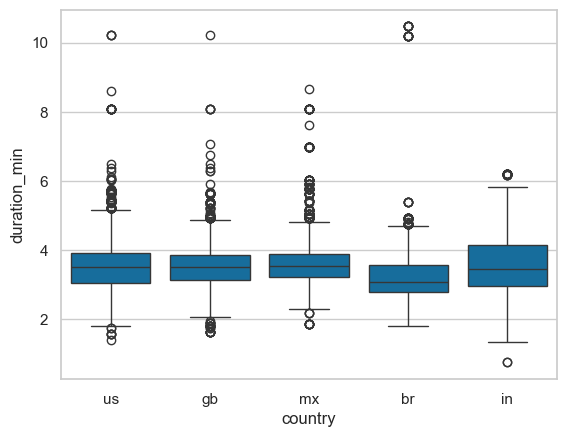

In [6]:
# Change duration in data from ms to s
df['duration_min'] = df['duration'] / 60000

# Drop songs that have a 0 runtime
df = df[df['duration_min'] > 0]
sns.boxplot(data=df, x='country', y='duration_min')

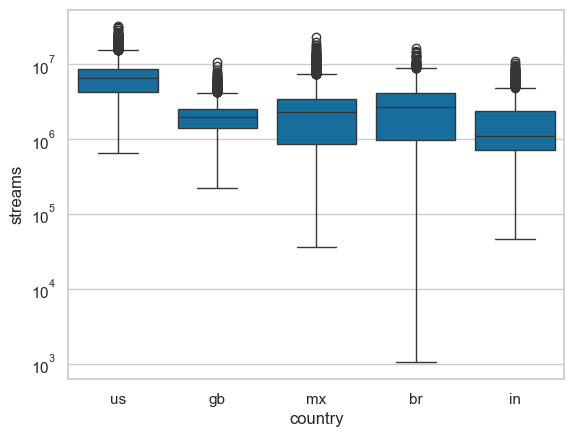

In [7]:
# How many streams does it take to get on the top ten list
sns.boxplot(data=df, x='country', y='streams'); plt.yscale('log')

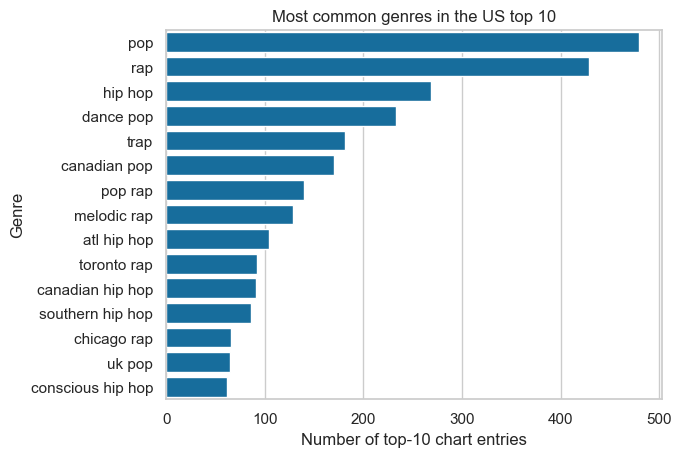

In [8]:
# Top genres and artists most common in the US top 10
us = df[df['country'] == 'us'].drop_duplicates('track_id')

import ast
genres = us['artist_genres'].dropna().apply(ast.literal_eval)

genres = genres.explode().dropna()

top = genres.value_counts().head(15)

sns.barplot(x=top.values, y=top.index)
plt.xlabel('Number of top-10 chart entries')
plt.ylabel('Genre')
plt.title('Most common genres in the US top 10')
plt.show()

In [ ]:
artists = us['artists'].dropna().apply(ast.literal_eval).explode().dropna()
top = artists.value_counts().head(15)
sns.barplot(x=top.values, y=top.index)
plt.xlabel("Number of top 10 chart entries")
plt.ylabel('Artist')
plt.title("Most common artists in the US top 10")
plt.show()